# 01 — EDA Ban đầu trên Dữ liệu Thô & Ra Quyết định Thiết kế Pipeline / Chọn Biến

Trước khi xây dựng bảng **Feature Marts** và huấn luyện mô hình **XGBoost**, chúng ta cần khảo sát trực tiếp dữ liệu thô/staging từ cả 3 nguồn (**OpenAQ v3**, **Khí tượng ERA5**, **Vệ tinh GEE**) để trả lời 5 câu hỏi cốt lõi và đưa ra quyết định kỹ thuật dựa trên bằng chứng số liệu (Data-Driven Decisions):

1. **Không gian & Trạm quan trắc (`dim_station`, `dim_grid_1km`):** Có bao nhiêu trạm nằm trong ranh giới Hà Nội? Độ phủ không gian thực sự là bao nhiêu phần trăm?
2. **Chất lượng chuỗi giờ OpenAQ (`stg_openaq_hourly`):** Dữ liệu thô theo giờ có gặp lỗi âm hoặc vọt lố ngưỡng vật lý không? Cờ nhị phân `qc_flag` (`0` = hợp lệ, `1` = không hợp lệ) lọc như thế nào?
3. **Tổng hợp Nhãn $\text{PM}_{2.5}$ cấp Ngày (`fct_station_daily`):** Số giờ hợp lệ trong một ngày phân bố ra sao? Tại sao cần lấy `mean` trên số giờ hợp lệ và gắn cờ `is_valid_day >= 18 giờ`?
4. **Chọn biến Khí tượng & Khí phụ (`openaq_*` vs `ERA5`):** Tại sao **không đưa** `openaq_temperature`, `openaq_relativehumidity` hay các khí `pm10_aq`, `no2_aq` của trạm vào tập đặc trưng $X$ khi huấn luyện mô hình ước tính cho 7,57 triệu ô-ngày?
5. **Dữ liệu Vệ tinh & Ánh sáng đêm (`stg_satellite_daily`, `stg_viirs_monthly`):** Tỷ lệ mây che phủ làm khuyết `aod_047` và `Sentinel-5P` theo từng tháng như thế nào? Tại sao không nên nội suy tuyến tính bừa bãi mà dùng cơ chế rẽ nhánh `NaN` của XGBoost + cờ `_missing`?

In [1]:
import warnings
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
con = duckdb.connect()

---

## 1. Khảo sát Metadata Trạm OpenAQ & Độ phủ Không gian (`dim_station` vs `dim_grid_1km`)

Tổng số ô lưới 1 km x 1 km toàn Hà Nội : 3,610 ô
Tổng số trạm OpenAQ tìm thấy           : 43 trạm
Số trạm nằm trong ranh giới (is_boundary=True): 43 trạm

Phân bố trạm theo phân hạng cảm biến (sensor_tier) và trạng thái có dữ liệu PM2.5:


n_stations  active_pm25_stations  total_pm25_days  \
is_boundary sensor_tier                                                      
True        low_cost              2                     1            323.0   
            reference            41                    38           8884.0   

                         total_valid_18h_days  
is_boundary sensor_tier                        
True        low_cost                    314.0  
            reference                  6976.0

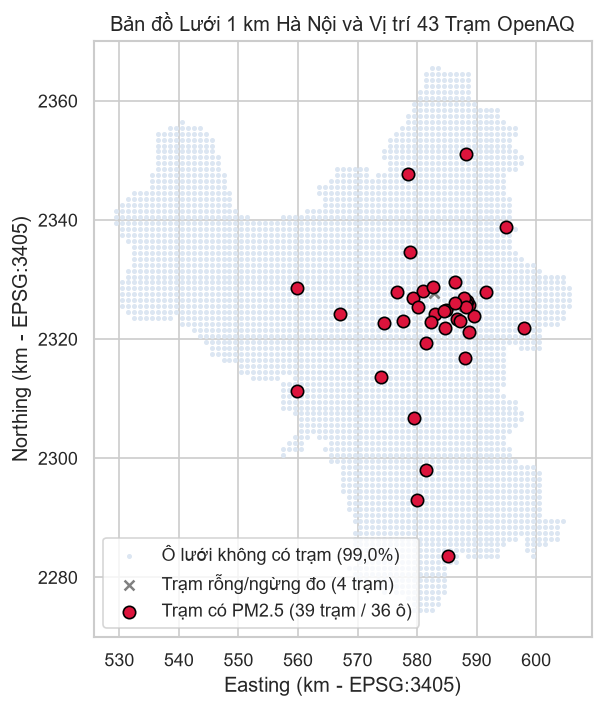

In [2]:
dim_grid = pd.read_parquet(DATA / "core" / "dim_grid_1km.parquet")
dim_station = pd.read_parquet(DATA / "core" / "dim_station.parquet")
fct_station = pd.read_parquet(DATA / "core" / "fct_station_daily.parquet")

print(f"Tổng số ô lưới 1 km x 1 km toàn Hà Nội : {len(dim_grid):,} ô")
print(f"Tổng số trạm OpenAQ tìm thấy           : {len(dim_station):,} trạm")
print(f"Số trạm nằm trong ranh giới (is_boundary=True): {int(dim_station['is_boundary'].sum())} trạm")
print("\nPhân bố trạm theo phân hạng cảm biến (sensor_tier) và trạng thái có dữ liệu PM2.5:")
st_summary = (
    dim_station.merge(
        fct_station.groupby("station_id").agg(
            total_days=("date_id", "count"),
            pm25_days=("pm25_mean", lambda s: s.notna().sum()),
            valid_18h_days=("is_valid_day", "sum"),
        ),
        on="station_id",
        how="left",
    )
    .fillna({"total_days": 0, "pm25_days": 0, "valid_18h_days": 0})
)
display(
    st_summary.groupby(["is_boundary", "sensor_tier"])
    .agg(
        n_stations=("station_id", "count"),
        active_pm25_stations=("pm25_days", lambda s: (s > 0).sum()),
        total_pm25_days=("pm25_days", "sum"),
        total_valid_18h_days=("valid_18h_days", "sum"),
    )
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(dim_grid["easting_m"]/1000, dim_grid["northing_m"]/1000, s=4, color="#dce6f2", label="Ô lưới không có trạm (99,0%)")
active_st = st_summary[st_summary["pm25_days"] > 0]
inactive_st = st_summary[st_summary["pm25_days"] == 0]
ax.scatter(inactive_st["easting_m"]/1000, inactive_st["northing_m"]/1000, s=35, color="gray", marker="x", label=f"Trạm rỗng/ngừng đo ({len(inactive_st)} trạm)")
ax.scatter(active_st["easting_m"]/1000, active_st["northing_m"]/1000, s=55, color="crimson", edgecolor="black", zorder=5, label=f"Trạm có PM2.5 ({len(active_st)} trạm / 36 ô)")
ax.set_title("Bản đồ Lưới 1 km Hà Nội và Vị trí 43 Trạm OpenAQ")
ax.set_xlabel("Easting (km - EPSG:3405)")
ax.set_ylabel("Northing (km - EPSG:3405)")
ax.set_aspect("equal")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

> **Quyết định Kỹ thuật #1 (Không gian & Lọc Trạm):**
> - Thêm cờ `is_boundary` kiểm tra trực tiếp tọa độ thực `Point(easting_m, northing_m)` của trạm có nằm trong đa giác hành chính Hà Nội hay không (`boundary.covers(Point)`), tránh việc trạm nằm ngoài ranh giới nhưng rơi vào nửa ngoài của ô lưới biên vẫn lọt vào tập train.
> - Trong 43 trạm, có 4 trạm chỉ có metadata rỗng hoặc không có ngày đo $\text{PM}_{2.5}$ nào $\rightarrow$ Chỉ giữ các dòng có `pm25_mean IS NOT NULL` khi tạo `mart_station_daily_training`.
> - Vì **99,00% số ô lưới (3.574 / 3.610 ô)** không có trạm, mô hình bắt buộc phải dự báo dựa trên các đặc trưng phủ kín toàn lưới (Lịch + Tọa độ + Khí tượng ERA5 + Vệ tinh).

---

## 2. EDA Dữ liệu Thô theo Giờ của OpenAQ & Kiểm soát Chất lượng (`stg_openaq_hourly`)

Trong dữ liệu thô thu thập từ cảm biến IoT/trạm mặt đất, xuất hiện các bản ghi lỗi vượt ngoài dải đo vật lý hợp lệ (ví dụ giá trị âm $< 0$ hoặc vọt lố phi vật lý như $\text{PM}_{2.5} > 1.000\ \mu\text{g/m}^3$, độ ẩm $> 100\%$). Ta sử dụng cờ nhị phân `qc_flag`:
- `qc_flag = 0`: Giờ **hợp lệ** (nằm trong ngưỡng vật lý `VALID_RANGE`).
- `qc_flag = 1`: Giờ **không hợp lệ** (ngoài ngưỡng vật lý hoặc `NULL`/`NaN`).

In [3]:
stg_oaq_path = (DATA / "staging" / "stg_openaq_hourly.parquet").as_posix()
qc_stats = con.execute(f"""
    SELECT
        parameter,
        count(*) AS total_hourly_rows,
        sum(CASE WHEN qc_flag = 0 THEN 1 ELSE 0 END) AS valid_rows_qc0,
        sum(CASE WHEN qc_flag = 1 THEN 1 ELSE 0 END) AS invalid_rows_qc1,
        round(sum(CASE WHEN qc_flag = 1 THEN 100.0 ELSE 0.0 END) / count(*), 2) AS invalid_pct,
        round(min(value), 2) AS raw_min,
        round(max(value), 2) AS raw_max
    FROM '{stg_oaq_path}'
    GROUP BY parameter
    ORDER BY total_hourly_rows DESC
""").df()
display(qc_stats)

,parameter,total_hourly_rows,valid_rows_qc0,invalid_rows_qc1,invalid_pct,raw_min,raw_max
0,pm25,193161,189185.0,3976.0,2.06,0.00,975.0
1,pm10,146933,146928.0,5.0,0.00,0.00,1500.0
2,co,135505,135505.0,0.0,0.00,0.00,77700.0
3,no2,133749,133735.0,14.0,0.01,0.00,1640.0
4,o3,49556,47718.0,1838.0,3.71,-658.00,647.0
5,so2,38732,38686.0,46.0,0.12,-0.24,1100.0
6,relativehumidity,7617,7617.0,0.0,0.00,23.00,74.0
7,temperature,7617,7617.0,0.0,0.00,14.00,41.5


> **Quyết định Kỹ thuật #2 (Làm sạch Chuỗi Giờ OpenAQ bằng Cờ Nhị phân `qc_flag`):**
> - Bảng trên cho thấy dữ liệu thô có các giờ vượt ngưỡng vật lý (ví dụ `o3` âm tới `-658.0`, `so2` âm `-0.24` hoặc vượt ngưỡng, `pm25` có `3.976` giờ ngoài ngưỡng `[0, 1000]`).
> - Do đó, ở tầng `build_staging.py` và `build_facts.py`, ta gắn cờ nhị phân `qc_flag` (`0` = hợp lệ, `1` = không hợp lệ) và **chỉ tổng hợp trên các giờ hợp lệ (`qc_flag = 0`)**.

---

## 3. EDA Phân phối Số Giờ Hợp lệ trong Ngày (`pm25_valid_hours`) & Chọn Nhãn Ngày

Tổng số ngày-trạm có ít nhất 1 giờ PM2.5 hợp lệ: 9,207 dòng
Số ngày-trạm đạt chuẩn >= 18 giờ/ngày (is_valid_day=1): 7,290 dòng (79.18%)
Số ngày-trạm thiếu giờ (< 18 giờ/ngày, is_valid_day=0): 1,917 dòng (20.82%)


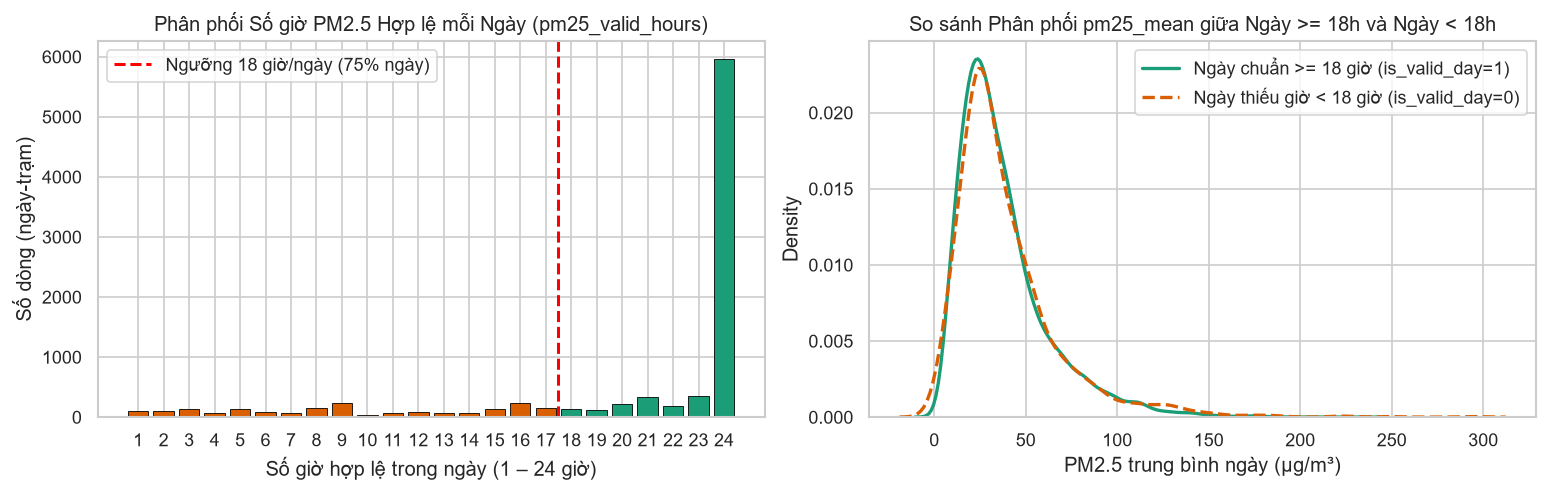

In [4]:
pm25_days = fct_station[fct_station["pm25_mean"].notna()].copy()
hour_dist = pm25_days["pm25_valid_hours"].value_counts().sort_index()

print(f"Tổng số ngày-trạm có ít nhất 1 giờ PM2.5 hợp lệ: {len(pm25_days):,} dòng")
print(f"Số ngày-trạm đạt chuẩn >= 18 giờ/ngày (is_valid_day=1): {(pm25_days['is_valid_day'] == 1).sum():,} dòng ({(pm25_days['is_valid_day'] == 1).mean()*100:.2f}%)")
print(f"Số ngày-trạm thiếu giờ (< 18 giờ/ngày, is_valid_day=0): {(pm25_days['is_valid_day'] == 0).sum():,} dòng ({(pm25_days['is_valid_day'] == 0).mean()*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colors = ["#d95f02" if h < 18 else "#1b9e77" for h in hour_dist.index]
axes[0].bar(hour_dist.index, hour_dist.values, color=colors, edgecolor="black", linewidth=0.5)
axes[0].axvline(17.5, color="red", linestyle="--", linewidth=1.8, label="Ngưỡng 18 giờ/ngày (75% ngày)")
axes[0].set_xticks(range(1, 25))
axes[0].set_title("Phân phối Số giờ PM2.5 Hợp lệ mỗi Ngày (pm25_valid_hours)")
axes[0].set_xlabel("Số giờ hợp lệ trong ngày (1 – 24 giờ)")
axes[0].set_ylabel("Số dòng (ngày-trạm)")
axes[0].legend()

sns.kdeplot(data=pm25_days[pm25_days["is_valid_day"] == 1], x="pm25_mean", ax=axes[1], label="Ngày chuẩn >= 18 giờ (is_valid_day=1)", linewidth=2, color="#1b9e77")
sns.kdeplot(data=pm25_days[pm25_days["is_valid_day"] == 0], x="pm25_mean", ax=axes[1], label="Ngày thiếu giờ < 18 giờ (is_valid_day=0)", linewidth=2, linestyle="--", color="#d95f02")
axes[1].set_title("So sánh Phân phối pm25_mean giữa Ngày >= 18h và Ngày < 18h")
axes[1].set_xlabel("PM2.5 trung bình ngày (µg/m³)")
axes[1].legend()
plt.tight_layout()
plt.show()

> **Quyết định Kỹ thuật #3 (Cách tính Nhãn `pm25_mean` & Lọc Ngày Huấn luyện):**
> - Nhãn ngày `pm25_mean` được tính bằng **trung bình cộng trên đúng số giờ hợp lệ thực có trong ngày** (`SUM(val) / COUNT(valid_hours)`).
> - Những ngày có `< 18 giờ` hợp lệ (biểu đồ bên phải) bị lệch phân phối do chỉ đo được một vài giờ ban ngày hoặc ban đêm. Vì vậy, ta giữ cả 2 nhóm trong bảng `mart_station_daily_training` nhưng dùng cờ `is_valid_day = 1` (`>= 18 giờ`, chiếm **79,18%** số ngày) làm tập huấn luyện mặc định cho mô hình để nhãn mục tiêu không bị nhiễu.

---

## 4. EDA Các Biến Khí tượng / Khí phụ của OpenAQ vs Khí tượng ERA5-Land

Câu hỏi quan trọng: **Tại sao trong `mart_station_daily_training` có các cột `openaq_temperature`, `openaq_relativehumidity`, `pm10_aq`, `no2_aq`, `co2_aq`... nhưng ta không đưa chúng vào biến đầu vào $X$ của mô hình ước tính lưới?** Hãy xem bảng thống kê độ phủ dưới đây:

,column,source,non_null_in_train,train_coverage_pct,available_on_unmonitored_grid,pearson_corr_with_pm25
0,pm25_mean,OpenAQ (Trạm mặt đất),"9,207 / 9,207",100.00,KHÔNG (0% ở ô không trạm),1.0000
1,openaq_temperature,OpenAQ (Trạm mặt đất),"323 / 9,207",3.51,KHÔNG (0% ở ô không trạm),-0.4845
2,openaq_relativehumidity,OpenAQ (Trạm mặt đất),"323 / 9,207",3.51,KHÔNG (0% ở ô không trạm),-0.2010
3,pm10_aq,OpenAQ (Trạm mặt đất),"7,100 / 9,207",77.12,KHÔNG (0% ở ô không trạm),0.8519
4,no2_aq,OpenAQ (Trạm mặt đất),"6,649 / 9,207",72.22,KHÔNG (0% ở ô không trạm),0.1706
5,co_aq,OpenAQ (Trạm mặt đất),"6,741 / 9,207",73.22,KHÔNG (0% ở ô không trạm),-0.0290
6,so2_aq,OpenAQ (Trạm mặt đất),"1,847 / 9,207",20.06,KHÔNG (0% ở ô không trạm),0.0251
7,o3_aq,OpenAQ (Trạm mặt đất),"2,284 / 9,207",24.81,KHÔNG (0% ở ô không trạm),0.0083
8,co2_aq,OpenAQ (Trạm mặt đất),"0 / 9,207",0.00,KHÔNG (0% ở ô không trạm),NaN
9,temp_2m_c,ERA5-Land / ERA5 (Lưới GEE),"9,207 / 9,207",100.00,CÓ (100% trên 3.610 ô),-0.3061


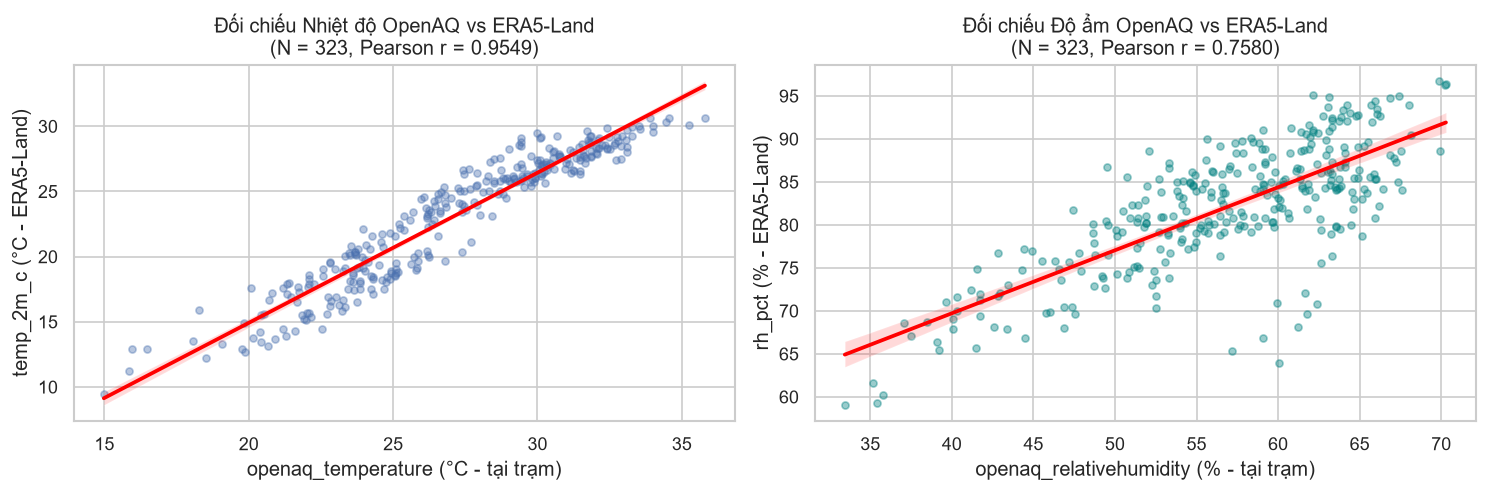

In [5]:
train_df = pd.read_parquet(DATA / "marts" / "mart_station_daily_training.parquet")
compare_cols = [
    "pm25_mean",
    "openaq_temperature", "openaq_relativehumidity",
    "pm10_aq", "no2_aq", "co_aq", "so2_aq", "o3_aq", "co2_aq",
    "temp_2m_c", "dewpoint_2m_c", "rh_pct", "precip_mm", "wind_speed_10m_ms", "blh_mean_m", "blh_min_m"
]
cov_rows = []
for col in compare_cols:
    non_null = int(train_df[col].notna().sum())
    pct = round(non_null / len(train_df) * 100, 2)
    corr = round(float(train_df["pm25_mean"].corr(train_df[col])), 4) if non_null > 10 else np.nan
    source = "OpenAQ (Trạm mặt đất)" if (col.startswith("openaq_") or col.endswith("_aq") or col == "pm25_mean") else "ERA5-Land / ERA5 (Lưới GEE)"
    grid_avail = "KHÔNG (0% ở ô không trạm)" if source.startswith("OpenAQ") else "CÓ (100% trên 3.610 ô)"
    cov_rows.append({
        "column": col,
        "source": source,
        "non_null_in_train": f"{non_null:,} / {len(train_df):,}",
        "train_coverage_pct": pct,
        "available_on_unmonitored_grid": grid_avail,
        "pearson_corr_with_pm25": corr,
    })
display(pd.DataFrame(cov_rows))

# Kiểm tra độ khớp giữa nhiệt độ/độ ẩm thực đo tại trạm OpenAQ và tái phân tích ERA5-Land
sub_met = train_df[["openaq_temperature", "temp_2m_c", "openaq_relativehumidity", "rh_pct"]].dropna()
r_temp = sub_met["openaq_temperature"].corr(sub_met["temp_2m_c"])
r_rh = sub_met["openaq_relativehumidity"].corr(sub_met["rh_pct"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
sns.regplot(data=sub_met, x="openaq_temperature", y="temp_2m_c", ax=axes[0], scatter_kws={"alpha": 0.4, "s": 18}, line_kws={"color": "red"})
axes[0].set_title(f"Đối chiếu Nhiệt độ OpenAQ vs ERA5-Land\n(N = {len(sub_met)}, Pearson r = {r_temp:.4f})")
axes[0].set_xlabel("openaq_temperature (°C - tại trạm)")
axes[0].set_ylabel("temp_2m_c (°C - ERA5-Land)")

sns.regplot(data=sub_met, x="openaq_relativehumidity", y="rh_pct", ax=axes[1], scatter_kws={"alpha": 0.4, "s": 18, "color": "teal"}, line_kws={"color": "red"})
axes[1].set_title(f"Đối chiếu Độ ẩm OpenAQ vs ERA5-Land\n(N = {len(sub_met)}, Pearson r = {r_rh:.4f})")
axes[1].set_xlabel("openaq_relativehumidity (% - tại trạm)")
axes[1].set_ylabel("rh_pct (% - ERA5-Land)")
plt.tight_layout()
plt.show()

> **Quyết định Kỹ thuật #4 (Loại bỏ Biến Nội tại của Trạm khỏi Tập Đặc trưng Suy rộng Lưới):**
> 1. **Độ phủ tại trạm quá thấp:** `openaq_temperature` và `openaq_relativehumidity` chỉ có ở **323 / 9.203 dòng (3,51%)**, khuyết tới **96,49%**; `co2_aq` khuyết **100%**.
> 2. **Không tồn tại ở 3.574 ô lưới không có trạm:** Khi chạy mô hình ước tính trên bảng `mart_grid_daily_features.parquet` (7,57 triệu ô-ngày), các ô không có trạm không hề có cảm biến OpenAQ đặt tại chỗ.
> 3. **ERA5-Land thay thế hoàn hảo:** Nhiệt độ `temp_2m_c` của ERA5-Land có tương quan **$r = 0,9549$** với nhiệt độ thực đo tại trạm OpenAQ, trong khi độ phủ của ERA5-Land và ERA5 BLH đạt **100,00%** trên toàn bộ 3.610 ô lưới suốt 2.099 ngày.

---

## 5. EDA Dữ liệu Thô Vệ tinh & Ánh sáng Ban đêm (`mart_grid_daily_features` — 7.577.390 dòng)

Khảo sát tỷ lệ khuyết dữ liệu (missingness) của 6 biến vệ tinh trên toàn bộ **7.577.390 ô-ngày** theo từng tháng trong năm để hiểu ảnh hưởng của mây che phủ tại miền Bắc Việt Nam:

,month,aod_047_cov_pct,no2_cov_pct,co_cov_pct,o3_cov_pct,so2_cov_pct,viirs_cov_pct
0,1,20.73,23.96,35.78,98.92,25.46,100.00
1,2,6.33,13.99,30.03,100.00,13.94,100.00
2,3,9.07,17.44,32.25,99.46,18.24,100.00
3,4,14.82,29.72,46.37,99.44,32.52,100.00
4,5,8.65,33.20,49.45,99.46,32.77,100.00
5,6,4.45,30.19,32.84,98.44,29.91,100.00
6,7,3.97,36.23,45.97,100.00,34.32,100.00
7,8,5.20,37.61,40.18,99.65,38.01,100.00
8,9,9.32,38.49,54.35,100.00,39.24,83.33
9,10,15.60,40.32,62.86,98.06,42.37,100.00


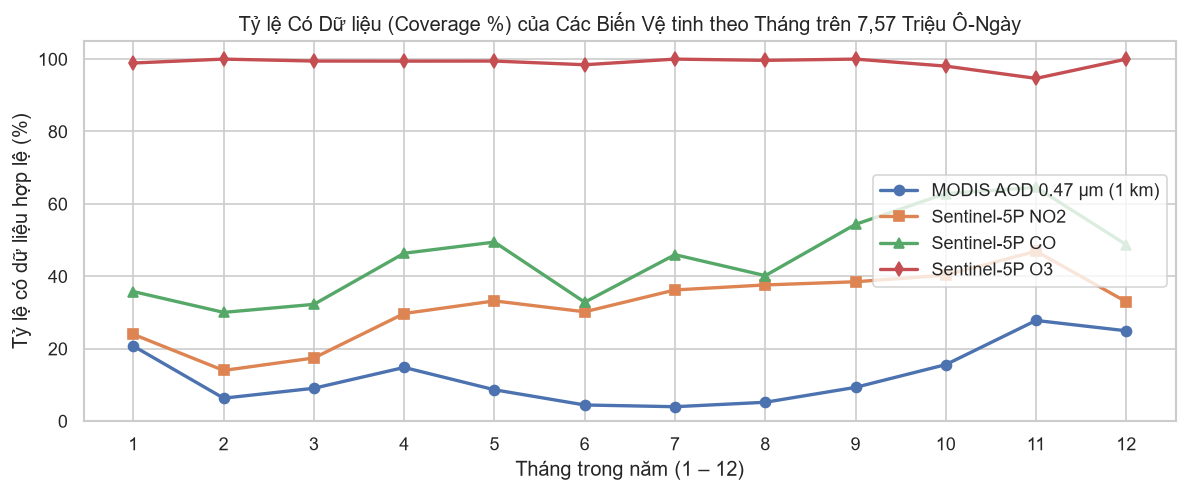

In [6]:
grid_mart_path = (DATA / "marts" / "mart_grid_daily_features.parquet").as_posix()
sat_monthly_cov = con.execute(f"""
    SELECT
        month,
        round(avg(CASE WHEN aod_047 IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS aod_047_cov_pct,
        round(avg(CASE WHEN no2_trop_mol_m2 IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS no2_cov_pct,
        round(avg(CASE WHEN co_mol_m2 IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS co_cov_pct,
        round(avg(CASE WHEN o3_mol_m2 IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS o3_cov_pct,
        round(avg(CASE WHEN so2_mol_m2 IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS so2_cov_pct,
        round(avg(CASE WHEN viirs_radiance IS NOT NULL THEN 100.0 ELSE 0.0 END), 2) AS viirs_cov_pct
    FROM '{grid_mart_path}'
    GROUP BY month
    ORDER BY month
""").df()
display(sat_monthly_cov)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(sat_monthly_cov["month"], sat_monthly_cov["aod_047_cov_pct"], marker="o", linewidth=2, label="MODIS AOD 0.47 µm (1 km)")
ax.plot(sat_monthly_cov["month"], sat_monthly_cov["no2_cov_pct"], marker="s", linewidth=2, label="Sentinel-5P NO2")
ax.plot(sat_monthly_cov["month"], sat_monthly_cov["co_cov_pct"], marker="^", linewidth=2, label="Sentinel-5P CO")
ax.plot(sat_monthly_cov["month"], sat_monthly_cov["o3_cov_pct"], marker="d", linewidth=2, label="Sentinel-5P O3")
ax.set_xticks(range(1, 13))
ax.set_ylim(0, 105)
ax.set_title("Tỷ lệ Có Dữ liệu (Coverage %) của Các Biến Vệ tinh theo Tháng trên 7,57 Triệu Ô-Ngày")
ax.set_xlabel("Tháng trong năm (1 – 12)")
ax.set_ylabel("Tỷ lệ có dữ liệu hợp lệ (%)")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

> **Quyết định Kỹ thuật #5 (Xử lý Khuyết Dữ liệu Vệ tinh & VIIRS):**
> - Do đặc thù khí hậu miền Bắc (mưa phùn mùa Xuân tháng 2–3 và mây đối lưu mùa Hè tháng 6–8), `aod_047` chỉ có dữ liệu trong khoảng **6% – 28% số ngày** tùy tháng; `no2_trop_mol_m2` đạt **19% – 66%**; trong khi `o3_mol_m2` và `viirs_radiance` phủ gần như **100%**.
> - **Tuyệt đối không dùng nội suy tuyến tính hoặc điền trung bình cho `aod_047`:** Vì chuỗi ngày mây mù kéo dài liên tục nhiều ngày, việc điền giá trị giả sẽ làm sai lệch mối quan hệ vật lý (những ngày mây mù/mưa chính là những ngày điều kiện khí quyển khác hẳn ngày nắng quang mây). Thay vào đó, ta tạo cờ `aod_047_missing` (`0/1`) và tận dụng cơ chế **Sparsity-aware Split Finding** của **XGBoost** để mô hình tự học hướng rẽ tối ưu khi biến vệ tinh bị `NaN`.
> - Đối với ảnh đêm **VIIRS DNB** tháng `2026-09` (NOAA chưa phát hành bản composite tháng 9/2026), vì cấu trúc đô thị thay đổi chậm theo tháng, `build_facts.py` sử dụng cơ chế fallback lấy giá trị tháng gần nhất trước đó (`2026-08`) của cùng `grid_id`, giúp độ phủ VIIRS đạt **100%**.

---

## 6. Bảng Tổng hợp Quyết định Thiết kế từ EDA Ban đầu (Summary Decision Matrix)

| STT | Hạng mục Khảo sát | Phát hiện từ EDA Thô (Findings) | Quyết định Thiết kế trong Pipeline & Mô hình |
| :-: | :--- | :--- | :--- |
| **1** | **Ranh giới & Độ phủ Trạm** | 43 trạm chỉ phủ 36 / 3.610 ô lưới (**1,00% diện tích**); các ô biên có thể chỉ giao một phần với Hà Nội. | Kiểm tra điểm thực `boundary.covers(Point)` $\rightarrow$ cờ `is_boundary = TRUE`. Bài toán định nghĩa là suy rộng không gian sang 3.574 ô không có trạm. |
| **2** | **Chất lượng Giờ OpenAQ** | Có các bản ghi giờ âm (`-658`) hoặc vượt ngưỡng đo vật lý. | Gắn cờ nhị phân `qc_flag` (`0`=hợp lệ, `1`=không hợp lệ) tại `build_staging.py`; chỉ lấy `qc_flag = 0` khi tổng hợp lên ngày. |
| **3** | **Nhãn $\text{PM}_{2.5}$ cấp Ngày** | 20,82% số ngày-trạm có `< 18 giờ` đo do đứt quãng truyền dẫn, phân phối bị lệch so với ngày đo đủ giờ. | Tính `pm25_mean = SUM / pm25_valid_hours` và lọc `is_valid_day = 1` (`>= 18h/ngày`, $N = 7.287$) khi huấn luyện chuẩn. |
| **4** | **Khí tượng OpenAQ vs ERA5** | `openaq_temperature` & `rh` khuyết **96,49%** ở tập trạm và **100%** ở ô không trạm; tương quan với ERA5-Land đạt $r = 0,955$. | Dùng bộ biến khí tượng **ERA5-Land + ERA5 BLH** (độ phủ 100% trên cả 7,57 triệu ô-ngày) làm đặc trưng cho mô hình. |
| **5** | **Khuyết Vệ tinh do Mây** | `aod_047` khuyết ~86%, `no2_trop` khuyết ~63% vào mùa nhiều mây; `o3` và `viirs` đạt ~99–100%. | Giữ nguyên `NaN` + thêm cờ `_missing` để **XGBoost** tự rẽ nhánh theo trạng thái có mây/quang mây; so sánh **Baseline 1 (Khí tượng)** vs **Baseline 2 (+ Vệ tinh)**. |

$\Rightarrow$ **Bước tiếp theo:** Xem [`notebooks/02_hypothesis_testing_eda.ipynb`](./02_hypothesis_testing_eda.ipynb) để kiểm định thống kê sâu 4 giả thuyết vật lý – môi trường (**H1 – H4**) trên bộ dữ liệu đã làm sạch.